# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv('public_transport.csv')

In [3]:
df

,timestamp,district_id,passenger_count,service_frequency,average_delay_minutes,vehicle_occupancy_percent,service_disruption_flag,sensor_status
0,2023-01-01 00:00:00,D01,527.0,30.0,1.255956,131.750000,0,Normal
1,2023-01-01 00:00:00,D02,199.0,30.0,0.587336,49.750000,0,Normal
2,2023-01-01 00:00:00,D03,28.0,30.0,0.505464,7.000000,0,Normal
3,2023-01-01 00:00:00,D04,632.0,30.0,6.850023,150.000000,0,Normal
4,2023-01-01 00:00:00,D05,533.0,30.0,6.485823,133.250000,0,Normal
...,...,...,...,...,...,...,...,...
526075,2025-12-31 23:00:00,D16,681.0,10.0,2.102535,56.750000,0,Normal
526076,2025-12-31 23:00:00,D17,1145.0,10.0,2.659989,95.416667,0,Normal
526077,2025-12-31 23:00:00,D18,5192.0,10.0,2.398194,150.000000,0,Normal
526078,2025-12-31 23:00:00,D19,3292.0,10.0,0.315060,150.000000,0,Normal


# Exploring Data

## Exploring columns and validating

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 526080 entries, 0 to 526079
Data columns (total 8 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   timestamp                  526080 non-null  str    
 1   district_id                526080 non-null  str    
 2   passenger_count            520838 non-null  float64
 3   service_frequency          520838 non-null  float64
 4   average_delay_minutes      520838 non-null  float64
 5   vehicle_occupancy_percent  520838 non-null  float64
 6   service_disruption_flag    526080 non-null  int64  
 7   sensor_status              526080 non-null  str    
dtypes: float64(4), int64(1), str(3)
memory usage: 46.2 MB


### Converting timestamps to datetime

In [5]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

### Checking for duplicated composite key (and dropping duplicates if existed)

In [6]:
# Checking for duplicated composite key
df[['timestamp', 'district_id']].duplicated().sum()

np.int64(0)

### Sorting data by districts then timestamps

In [7]:
df = df.sort_values(['district_id', 'timestamp']).reset_index(drop=True)

### Understanding columns + feature engineering (if needed)

In [25]:
df.describe()

,timestamp,passenger_count,service_frequency,average_delay_minutes,vehicle_occupancy_percent,service_disruption_flag
count,520838,520838.000000,520838.000000,520838.000000,520838.000000,520838.000000
mean,2024-07-01 21:22:02.882737,3875.380998,13.124878,5.350368,102.935985,0.027536
min,2023-01-01 00:00:00,0.000000,5.000000,0.000002,0.000000,0.000000
25%,2023-10-01 21:00:00,442.000000,10.000000,2.020853,48.250000,0.000000
50%,2024-07-01 19:00:00,1668.000000,10.000000,3.418913,147.500000,0.000000
75%,2025-04-01 21:00:00,5367.000000,10.000000,5.409064,150.000000,0.000000
max,2025-12-31 23:00:00,65775.000000,30.000000,97.558212,150.000000,1.000000
std,NaN,5406.190616,8.876326,9.635373,55.207297,0.163640


In [9]:
df['sensor_status'].unique()

<ArrowStringArray>
['Normal', 'Outage-Affected', 'Communication-Loss']
Length: 3, dtype: str

In [10]:
df['sensor_status'].value_counts()

sensor_status
Normal                520838
Communication-Loss      5151
Outage-Affected           91
Name: count, dtype: int64

In [11]:
df['service_disruption_flag'].value_counts()

service_disruption_flag
0    511504
1     14576
Name: count, dtype: int64

## Checking nulls

In [24]:
df.isnull().sum()

timestamp                    0
district_id                  0
passenger_count              0
service_frequency            0
average_delay_minutes        0
vehicle_occupancy_percent    0
service_disruption_flag      0
sensor_status                0
dtype: int64

In [13]:
# Check if the nulls is due to abnormal sensor state
sensor_cols = ['passenger_count', 'service_frequency', 'average_delay_minutes','vehicle_occupancy_percent']
for col in sensor_cols:
    print(f"{col}: {((df[col].isnull()) & (df['sensor_status'] == 'Normal')).sum()}")

# Since all the results are 0 that means There wasn't any observation where it was null while the sensor is normally working

passenger_count: 0
service_frequency: 0
average_delay_minutes: 0
vehicle_occupancy_percent: 0


In [14]:
# Check how many missing value happened in every detection cause of (Communication-Loss)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Communication-Loss')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")

passenger_count: 5151 which is 98.26% of total null detections
service_frequency: 5151 which is 98.26% of total null detections
average_delay_minutes: 5151 which is 98.26% of total null detections
vehicle_occupancy_percent: 5151 which is 98.26% of total null detections


In [15]:
# Check how many missing value happened in every detection cause of (Outage-Affected)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Outage-Affected')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")
    

passenger_count: 91 which is 1.74% of total null detections
service_frequency: 91 which is 1.74% of total null detections
average_delay_minutes: 91 which is 1.74% of total null detections
vehicle_occupancy_percent: 91 which is 1.74% of total null detections


## Checking outliers

In [16]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return df[(df[column] < lower) | (df[column] > upper)]

for col in ['passenger_count', 'service_frequency', 'average_delay_minutes', 'vehicle_occupancy_percent']:
    print(f'{col}: {len(find_outliers_iqr(df, col))}, mean: {df[col].mean():.2f}, above upper = {len(find_outliers_iqr(df, col)[df[col] > df[col].mean()])}, below lower = {len(find_outliers_iqr(df, col)[df[col] < df[col].mean()])}')

passenger_count: 33335, mean: 3875.38, above upper = 33335, below lower = 0
service_frequency: 217089, mean: 13.12, above upper = 108520, below lower = 108569
average_delay_minutes: 27318, mean: 5.35, above upper = 27318, below lower = 0
vehicle_occupancy_percent: 0, mean: 102.94, above upper = 0, below lower = 0


## Validating Outliers

### Passenger count

In [17]:
find_outliers_iqr(df, 'passenger_count')

,timestamp,district_id,passenger_count,service_frequency,average_delay_minutes,vehicle_occupancy_percent,service_disruption_flag,sensor_status
31,2023-01-02 07:00:00,D01,22907.0,5.0,6.887136,150.0,0,Normal
32,2023-01-02 08:00:00,D01,22937.0,5.0,11.544500,150.0,0,Normal
33,2023-01-02 09:00:00,D01,22869.0,5.0,45.369353,150.0,1,Normal
40,2023-01-02 16:00:00,D01,22608.0,5.0,6.635083,150.0,0,Normal
41,2023-01-02 17:00:00,D01,22730.0,5.0,7.371649,150.0,0,Normal
...,...,...,...,...,...,...,...,...
495042,2025-06-17 18:00:00,D19,17858.0,5.0,10.582118,150.0,0,Normal
495043,2025-06-17 19:00:00,D19,17787.0,5.0,9.697667,150.0,0,Normal
507810,2023-12-01 18:00:00,D20,13717.0,5.0,7.913476,150.0,0,Normal
518968,2025-03-10 16:00:00,D20,13730.0,5.0,7.358327,150.0,0,Normal


### Average delay

In [18]:
find_outliers_iqr(df, 'average_delay_minutes')

,timestamp,district_id,passenger_count,service_frequency,average_delay_minutes,vehicle_occupancy_percent,service_disruption_flag,sensor_status
32,2023-01-02 08:00:00,D01,22937.0,5.0,11.544500,150.0,0,Normal
33,2023-01-02 09:00:00,D01,22869.0,5.0,45.369353,150.0,1,Normal
55,2023-01-03 07:00:00,D01,22600.0,5.0,10.534567,150.0,0,Normal
65,2023-01-03 17:00:00,D01,22852.0,5.0,10.948454,150.0,0,Normal
110,2023-01-05 14:00:00,D01,9127.0,10.0,11.162636,150.0,0,Normal
...,...,...,...,...,...,...,...,...
525945,2025-12-26 09:00:00,D20,7635.0,5.0,16.698047,150.0,0,Normal
526049,2025-12-30 17:00:00,D20,7658.0,5.0,61.525307,150.0,1,Normal
526050,2025-12-30 18:00:00,D20,7742.0,5.0,70.578414,150.0,1,Normal
526051,2025-12-30 19:00:00,D20,7701.0,5.0,16.965513,150.0,0,Normal


### Service frequency

In [19]:
find_outliers_iqr(df, 'service_frequency')

,timestamp,district_id,passenger_count,service_frequency,average_delay_minutes,vehicle_occupancy_percent,service_disruption_flag,sensor_status
0,2023-01-01 00:00:00,D01,527.0,30.0,1.255956,131.75,0,Normal
1,2023-01-01 01:00:00,D01,519.0,30.0,1.992278,129.75,0,Normal
2,2023-01-01 02:00:00,D01,556.0,30.0,1.811894,139.00,0,Normal
3,2023-01-01 03:00:00,D01,561.0,30.0,1.496537,140.25,0,Normal
4,2023-01-01 04:00:00,D01,584.0,30.0,1.926293,146.00,0,Normal
...,...,...,...,...,...,...,...,...
526065,2025-12-31 09:00:00,D20,6677.0,5.0,4.581486,150.00,0,Normal
526072,2025-12-31 16:00:00,D20,6556.0,5.0,3.795745,150.00,0,Normal
526073,2025-12-31 17:00:00,D20,6703.0,5.0,4.265056,150.00,0,Normal
526074,2025-12-31 18:00:00,D20,6605.0,5.0,4.909652,150.00,0,Normal


# Important KPIs

## Transit ridership and average delay

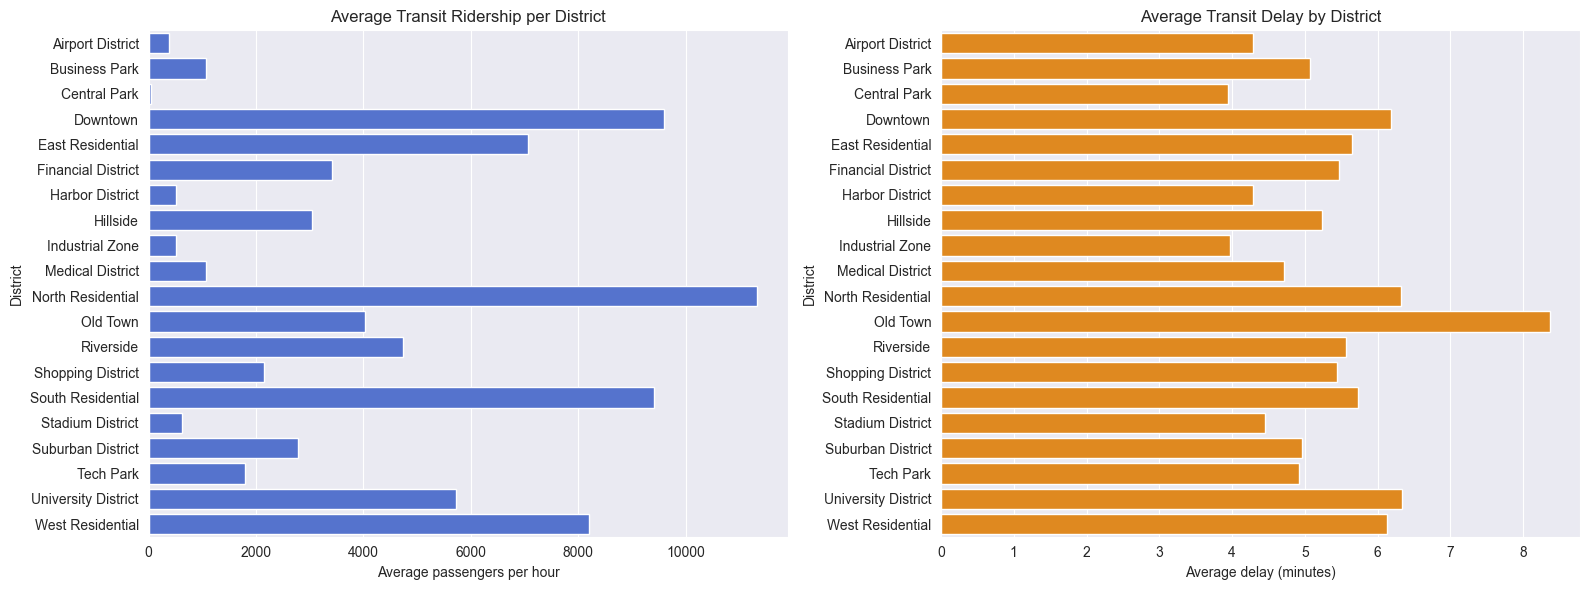

In [20]:
districts = pd.read_csv('districts.csv')
districts_transport = districts.merge(df, on='district_id')

transit_kpi = districts_transport.groupby('district_name').agg(
    average_ridership=('passenger_count', 'mean'),
    average_delay=('average_delay_minutes', 'mean')
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(transit_kpi, x='average_ridership', y='district_name', color='royalblue', ax=ax[0])
ax[0].set_title('Average Transit Ridership per District')
ax[0].set_xlabel('Average passengers per hour')
ax[0].set_ylabel('District')

sns.barplot(transit_kpi, x='average_delay', y='district_name', color='darkorange', ax=ax[1])
ax[1].set_title('Average Transit Delay by District')
ax[1].set_xlabel('Average delay (minutes)')
ax[1].set_ylabel('District')

plt.tight_layout()
plt.show()

## Vehicle occupancy

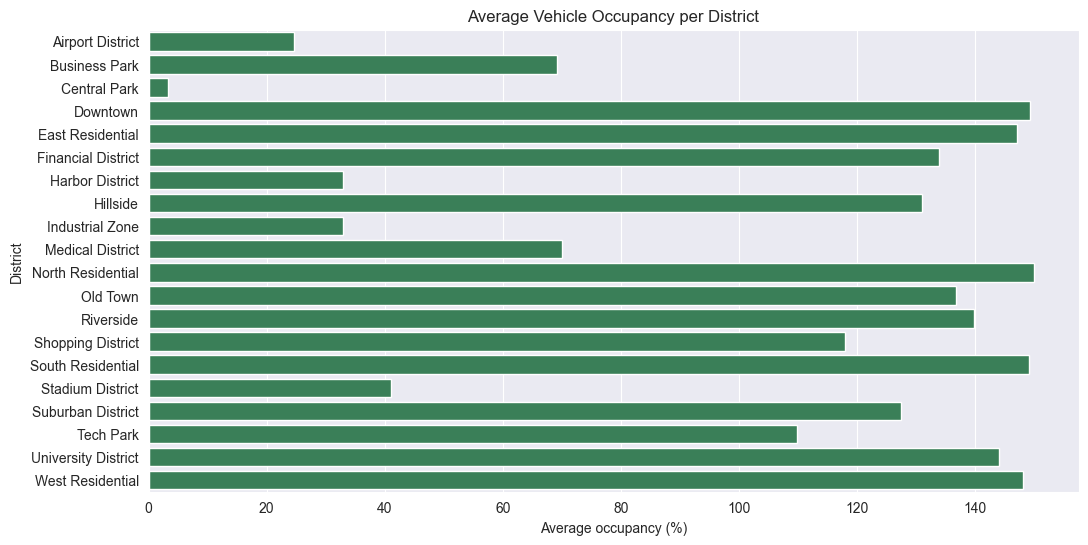

In [21]:
occupancy = districts_transport.groupby('district_name').agg(
    average_occupancy=('vehicle_occupancy_percent', 'mean')
).reset_index()

sns.barplot(occupancy, x='average_occupancy', y='district_name', color='seagreen')
plt.title('Average Vehicle Occupancy per District')
plt.xlabel('Average occupancy (%)')
plt.ylabel('District')
plt.show()

## Transit disruption rate

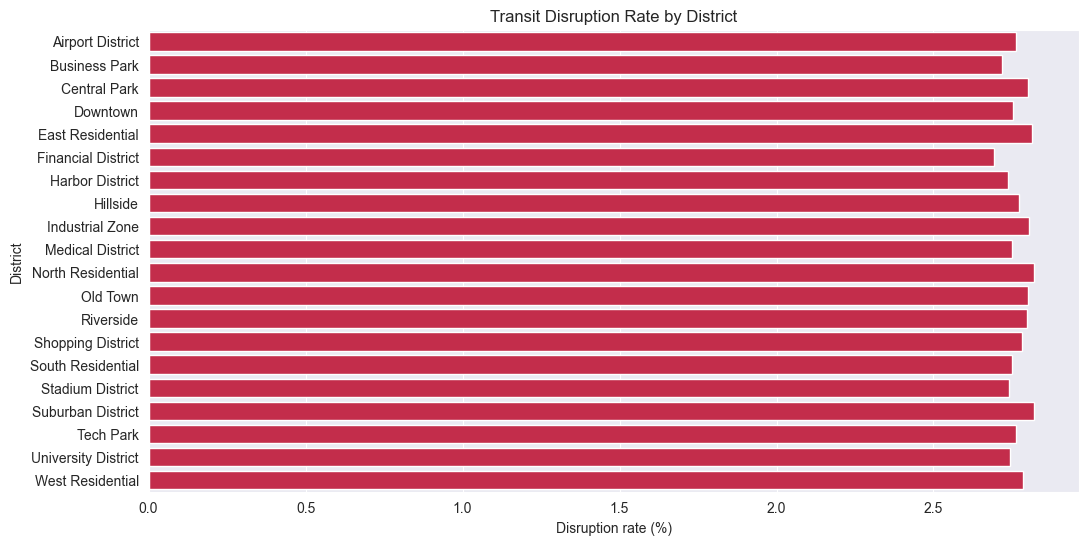

In [22]:
disruption_rate = districts_transport.groupby('district_name').agg(
    disruption_rate=('service_disruption_flag', lambda x: x.mean() * 100)
).reset_index()

sns.barplot(disruption_rate, x='disruption_rate', y='district_name', color='crimson')
plt.title('Transit Disruption Rate by District')
plt.xlabel('Disruption rate (%)')
plt.ylabel('District')
plt.show()

# Data Cleaning

## Handling Nulls

In [23]:
df = df.sort_values(['district_id', 'timestamp'])
cleaned_public_transport = df.ffill().bfill()
cleaned_public_transport.to_csv('data/cleaned_public_transport.csv', index=False)